<a href="https://colab.research.google.com/github/d03antony-ai/labo-momentum/blob/main/01_momentum_replication.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/tmp/ipykernel_4143/1358309632.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf .download("SPY", start="2010-01-01")
[*********************100%***********************]  1 of 1 completed


<Axes: xlabel='Date'>

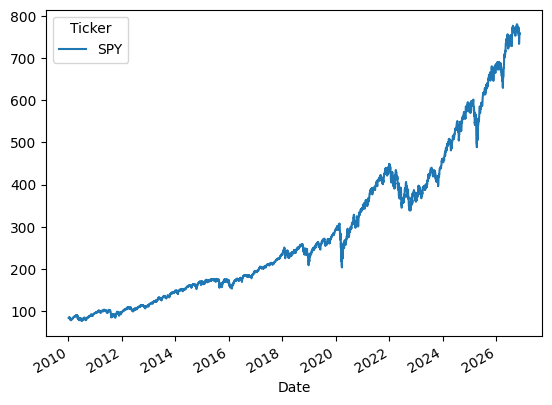

In [1]:
!pip install yfinance
import yfinance as yf
df = yf .download("SPY", start="2010-01-01")
df ["Close"].plot()

<Axes: xlabel='Date'>

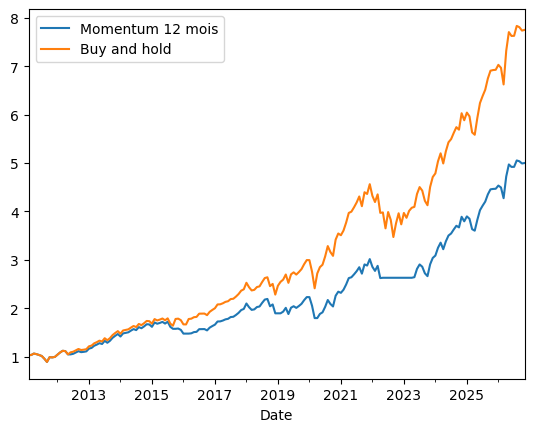

In [11]:
import pandas as pd

prix = df["Close"].squeeze().resample("ME").last()
rend = prix.pct_change()
signal = (prix > prix.shift(12)).astype(float).shift(1)

data =pd.DataFrame({"rend": rend, "signal": signal}).iloc[13:]
data["Momentum 12 mois"] = (1 + data["rend"]* data["signal"]).cumprod()
data["Buy and hold"] = (1+data["rend"]).cumprod()
data[["Momentum 12 mois", "Buy and hold"]].plot()